# Прогнозирование цены недвижимости
Модели обучаются на `real_estate_data.csv`, проверяется на 20 объектах из `test_real_estate_samples.csv`.


In [1]:
FIO   = "Хабибуллин Артём Альбертович"
GROUP = "23П-4"

TRAIN_PATH = "real_estate_data.csv"
TEST_PATH  = "test_real_estate_samples.csv"
OUT_PATH   = "result_real_estate_samples.csv"

TARGET = "price"
RANDOM_STATE = 42

TRAIN_ROWS = 250_000    
N_JOBS = -1              


## 1. Данные


In [2]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (HistGradientBoostingRegressor, RandomForestRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, BaggingRegressor)
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)
print("train:", train.shape, "| test:", test.shape)


train: (403487, 17) | test: (20, 17)


## 2. Очистка данных, признаки и EDA


In [3]:
def parse_num(x):
    if pd.isna(x):
        return np.nan
    nums = [float(n) for n in re.findall(r"\d+", str(x))]
    return float(np.mean(nums)) if nums else np.nan


def parse_rooms(x):
    if pd.isna(x):
        return np.nan, np.nan
    m = re.fullmatch(r"\s*(\d+)\s*\+\s*(\d+)\s*", str(x))
    return (float(m.group(1)), float(m.group(2))) if m else (np.nan, np.nan)


def floor_category(x):
    if pd.isna(x):
        return "missing"
    return "numeric" if re.search(r"\d", str(x)) else str(x).strip()


# сводка по сырым данным для EDA (до очистки)
raw_summary = {"rows": len(train),
               "missing": train.isna().mean().mul(100).sort_values(ascending=False),
               "currency": train["price_currency"].value_counts(),
               "listing": train["listing_type"].value_counts().sort_index()}

# ---- очистка train ----
removed = {}
n0 = len(train)

leak = train["id"].isin(test["id"])                 
removed["тестовые объекты"] = int(leak.sum())
train = train.loc[~leak]

ok = (train["price_currency"] == "TRY") & train["listing_type"].isin([1, 2])
removed["не TRY или тип сделки не 1/2"] = int((~ok).sum())
train = train.loc[ok]

train[TARGET] = pd.to_numeric(train[TARGET], errors="coerce")
bad = train[TARGET].isna() | ~np.isfinite(train[TARGET]) | (train[TARGET] <= 0)
removed["некорректная цена"] = int(bad.sum())
train = train.loc[~bad].reset_index(drop=True)
print("Удалено строк:", removed, "| осталось:", len(train), "из", n0)

if TRAIN_ROWS and len(train) > TRAIN_ROWS:
    train = train.sample(TRAIN_ROWS, random_state=RANDOM_STATE).reset_index(drop=True)
print("Строк для обучения:", len(train))

# выбросы цены обрезаем по 1–99% отдельно для продажи и аренды
train["price_w"] = train[TARGET]
for lt, g in train.groupby("listing_type"):
    lo, hi = g[TARGET].quantile([0.01, 0.99])
    train.loc[g.index, "price_w"] = g[TARGET].clip(lo, hi)

# статистики площади — только по train
size_s = pd.to_numeric(train["size"], errors="coerce").where(lambda s: s > 0)
STATS = {"size_lo": size_s.quantile(0.01), "size_hi": size_s.quantile(0.99),
         "size_med": size_s.median(),
         "size_med_by_subtype": size_s.groupby(train["sub_type"]).median().to_dict()}


def make_features(df, st=STATS):
    out = pd.DataFrame(index=df.index)

    size = pd.to_numeric(df["size"], errors="coerce").where(lambda s: s > 0)
    out["size_missing"] = size.isna().astype(int)
    med = df["sub_type"].map(st["size_med_by_subtype"]).fillna(st["size_med"])
    out["log_size"] = np.log1p(size.fillna(med).clip(st["size_lo"], st["size_hi"]))

    out["tom"]               = pd.to_numeric(df["tom"], errors="coerce")
    out["building_age"]      = df["building_age"].map(parse_num)
    out["total_floor_count"] = df["total_floor_count"].map(parse_num)
    out["floor_no_num"]      = df["floor_no"].map(parse_num)
    out["listing_type"]      = df["listing_type"]

    rooms = df["room_count"].map(parse_rooms)
    out["rooms"]       = rooms.map(lambda t: t[0])
    out["halls"]       = rooms.map(lambda t: t[1])
    out["rooms_total"] = out["rooms"] + out["halls"]
    out["start_month"] = pd.to_datetime(df["start_date"], format="%m/%d/%y", errors="coerce").dt.month

    out["sub_type"]     = df["sub_type"].fillna("missing")
    out["heating_type"] = df["heating_type"].fillna("missing")
    out["floor_cat"]    = df["floor_no"].map(floor_category)

    addr = df["address"].fillna("").str.split("/", expand=True)
    for i in range(3):
        if i not in addr.columns:
            addr[i] = ""
    city = addr[0].fillna("")
    dist = city + "/" + addr[1].fillna("")
    neig = dist + "/" + addr[2].fillna("")
    lt = df["listing_type"].astype(str)
    out["city"]        = city.replace("", "missing")
    out["te_district"] = lt + "|" + dist
    out["te_neigh"]    = lt + "|" + neig
    out["te_subtype"]  = lt + "|" + df["sub_type"].fillna("missing")
    return out


X_all  = make_features(train)
y_all  = train["price_w"].astype(float)
X_test = make_features(test).reindex(columns=X_all.columns)
y_test = test[TARGET].astype(float)

num_cols = ["log_size", "size_missing", "tom", "building_age", "total_floor_count", "floor_no_num",
            "listing_type", "rooms", "halls", "rooms_total", "start_month"]
cat_cols = ["sub_type", "heating_type", "floor_cat", "city"]
te_cols  = ["te_district", "te_neigh", "te_subtype"]


Удалено строк: {'тестовые объекты': 20, 'не TRY или тип сделки не 1/2': 5043, 'некорректная цена': 45} | осталось: 398379 из 403487
Строк для обучения: 250000


## 2.1 EDA: качество исходных данных


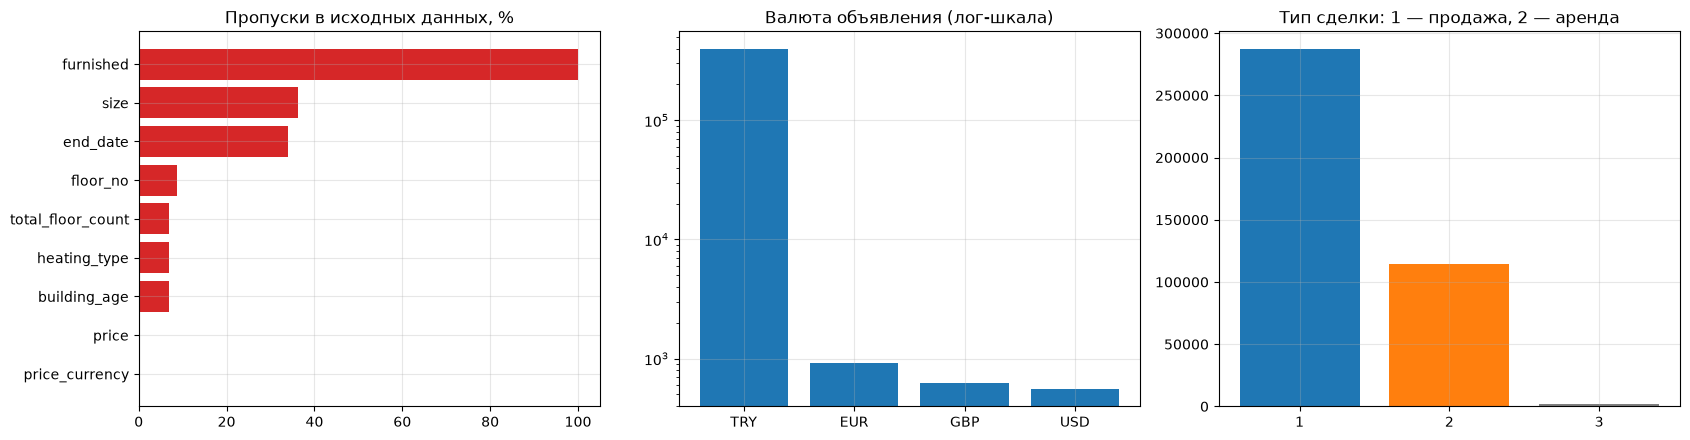

Итоговая статистика цены по типам сделки (после чистки, до обрезки выбросов):


,count,mean,std,min,25%,50%,75%,max
listing_type,,,,,,,,
1,178503.0,499247.0,6506063.0,1.0,185000.0,270000.0,420000.0,2.000000e+09
2,71497.0,17881.0,3741858.0,3.0,850.0,1200.0,1700.0,9.999991e+08


In [4]:
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
miss = raw_summary["missing"]
miss = miss[miss > 0].sort_values()
ax[0].barh(miss.index, miss.values, color="tab:red")
ax[0].set_title("Пропуски в исходных данных, %")

cur = raw_summary["currency"]
ax[1].bar(cur.index.astype(str), cur.values, color="tab:blue")
ax[1].set_yscale("log")
ax[1].set_title("Валюта объявления (лог-шкала)")

lt_cnt = raw_summary["listing"]
ax[2].bar(lt_cnt.index.astype(str), lt_cnt.values, color=["tab:blue", "tab:orange", "tab:gray"][:len(lt_cnt)])
ax[2].set_title("Тип сделки: 1 — продажа, 2 — аренда")
plt.tight_layout(); plt.show()

print("Итоговая статистика цены по типам сделки (после чистки, до обрезки выбросов):")
display(train.groupby("listing_type")[TARGET].describe().round(0))


## 2.2 EDA: цена и площадь


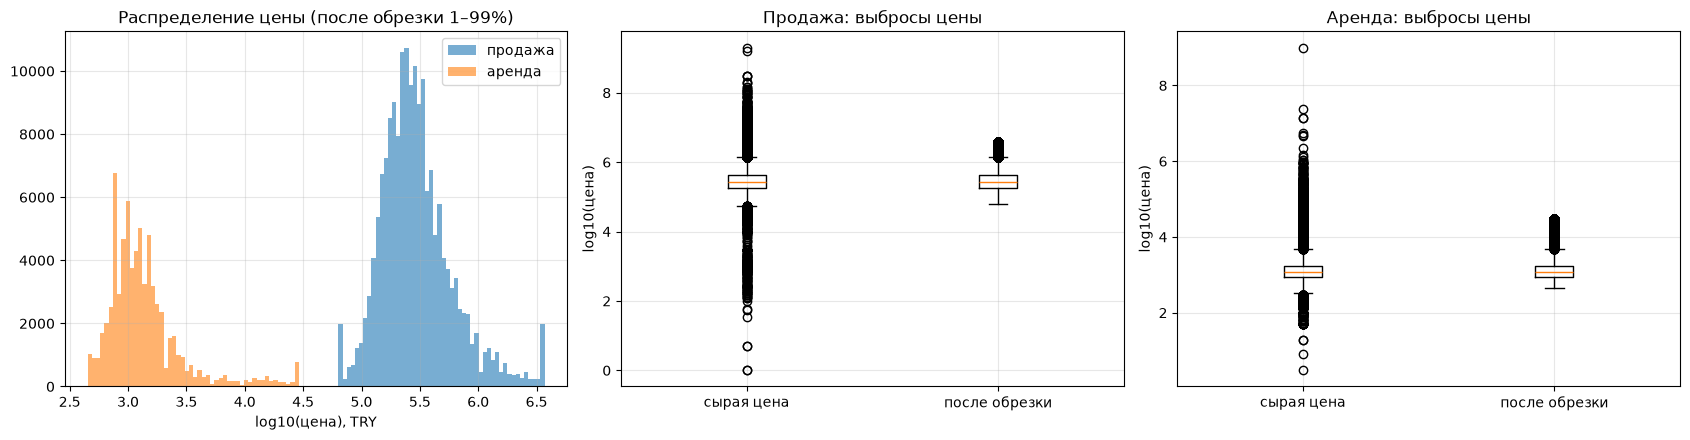

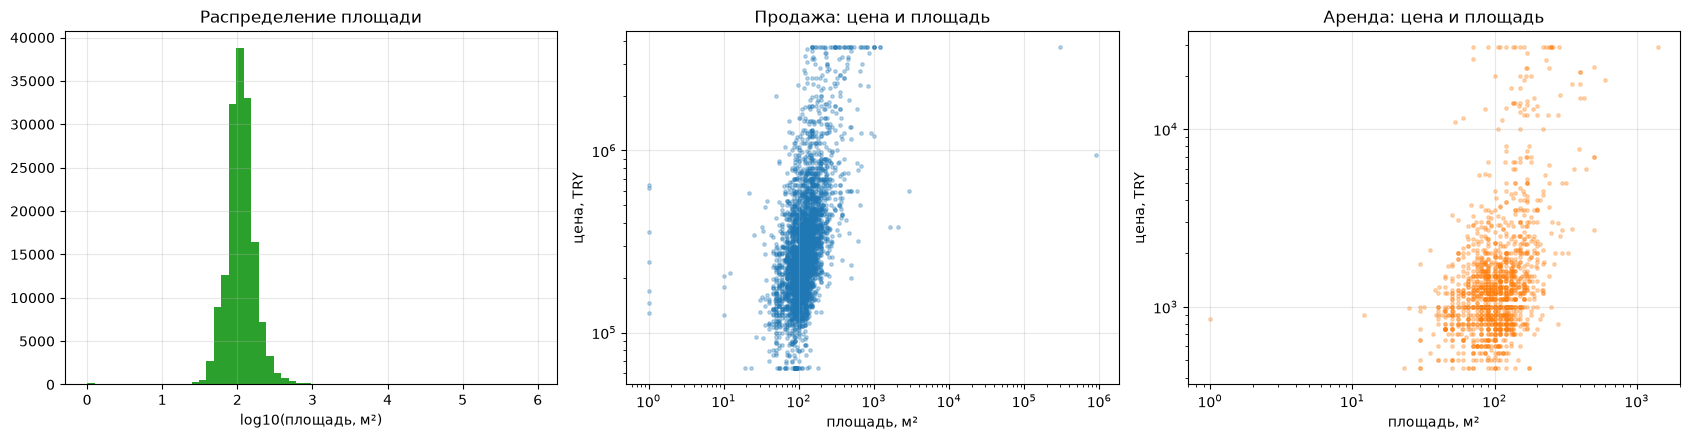

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for lt, name, col in ((1, "продажа", "tab:blue"), (2, "аренда", "tab:orange")):
    ax[0].hist(np.log10(train.loc[train["listing_type"] == lt, "price_w"]), bins=50, alpha=0.6, label=name, color=col)
ax[0].set_xlabel("log10(цена), TRY"); ax[0].set_title("Распределение цены (после обрезки 1–99%)"); ax[0].legend()

for a, lt, name in ((ax[1], 1, "продажа"), (ax[2], 2, "аренда")):
    g = train.loc[train["listing_type"] == lt]
    a.boxplot([np.log10(g[TARGET]), np.log10(g["price_w"])], showfliers=True)
    a.set_xticklabels(["сырая цена", "после обрезки"])
    a.set_ylabel("log10(цена)"); a.set_title(f"{name.capitalize()}: выбросы цены")
plt.tight_layout(); plt.show()

# площадь и связь с ценой
eda = train.sample(min(8000, len(train)), random_state=RANDOM_STATE).copy()
eda["size_n"] = pd.to_numeric(eda["size"], errors="coerce").where(lambda s: s > 0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].hist(np.log10(pd.to_numeric(train["size"], errors="coerce").where(lambda s: s > 0).dropna()),
           bins=60, color="tab:green")
ax[0].set_xlabel("log10(площадь, м²)"); ax[0].set_title("Распределение площади")
for a, lt, name, col in ((ax[1], 1, "продажа", "tab:blue"), (ax[2], 2, "аренда", "tab:orange")):
    g = eda[(eda["listing_type"] == lt) & eda["size_n"].notna()]
    a.scatter(g["size_n"], g["price_w"], s=6, alpha=0.3, color=col)
    a.set_xscale("log"); a.set_yscale("log")
    a.set_xlabel("площадь, м²"); a.set_ylabel("цена, TRY")
    a.set_title(f"{name.capitalize()}: цена и площадь")
plt.tight_layout(); plt.show()


## 2.3 EDA: типы жилья и география


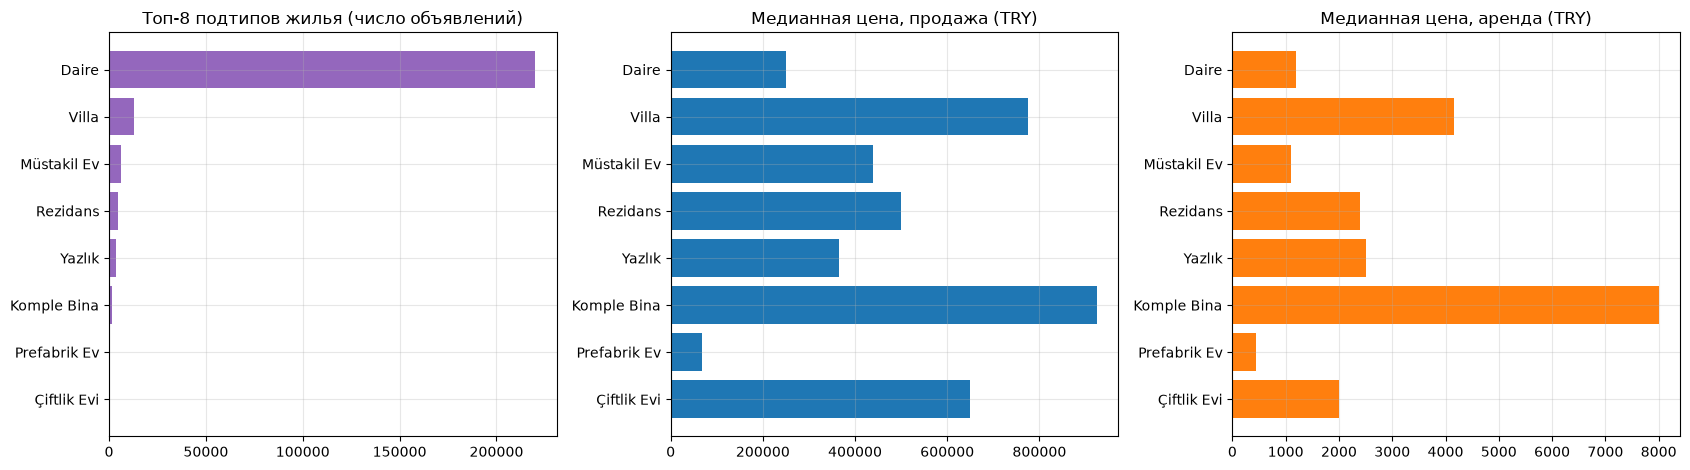

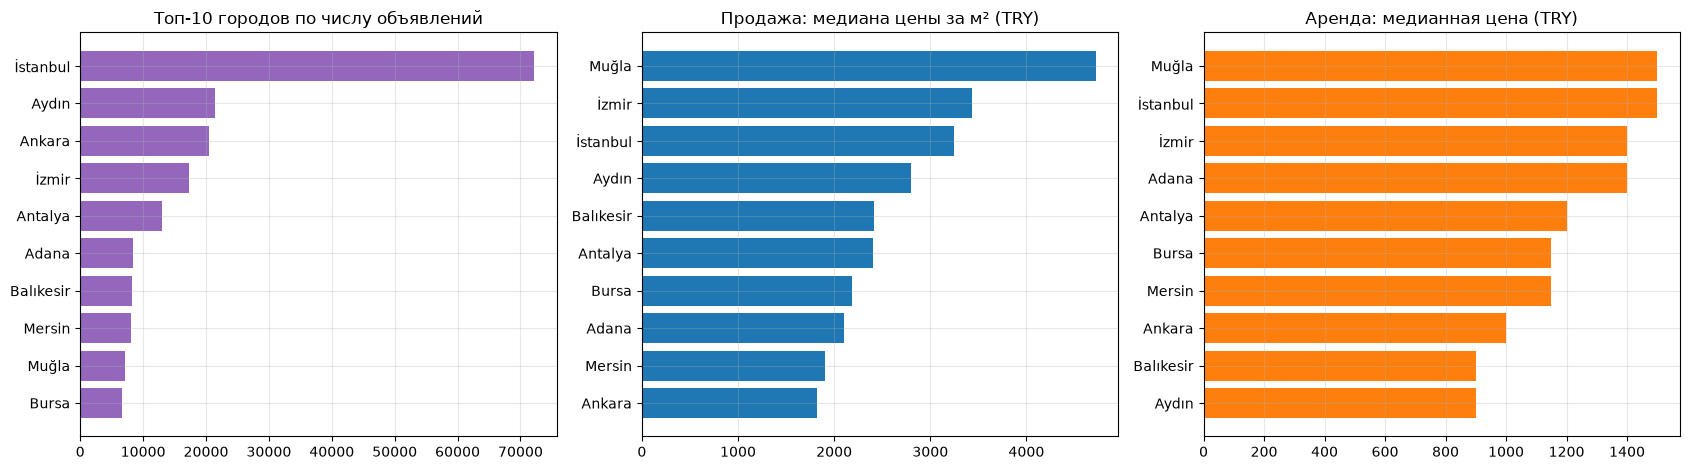

In [6]:
top_sub = train["sub_type"].value_counts().head(8)
med_sub = train.groupby(["sub_type", "listing_type"])["price_w"].median().unstack()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].barh(top_sub.index[::-1], top_sub.values[::-1], color="tab:purple")
ax[0].set_title("Топ-8 подтипов жилья (число объявлений)")
for a, lt, name, col in ((ax[1], 1, "продажа", "tab:blue"), (ax[2], 2, "аренда", "tab:orange")):
    v = med_sub.loc[top_sub.index, lt]
    a.barh(v.index[::-1], v.values[::-1], color=col)
    a.set_title(f"Медианная цена, {name} (TRY)")
plt.tight_layout(); plt.show()

city = train["address"].fillna("").str.split("/").str[0]
size_pos = pd.to_numeric(train["size"], errors="coerce").where(lambda s: s > 0)
geo = pd.DataFrame({"city": city, "lt": train["listing_type"], "price": train["price_w"],
                    "per_m2": train["price_w"] / size_pos})
top_city = geo["city"].value_counts().head(10).index

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cnt = geo["city"].value_counts().head(10)
ax[0].barh(cnt.index[::-1], cnt.values[::-1], color="tab:purple")
ax[0].set_title("Топ-10 городов по числу объявлений")
m_sale = geo[geo["lt"] == 1].groupby("city")["per_m2"].median().reindex(top_city).dropna().sort_values()
ax[1].barh(m_sale.index, m_sale.values, color="tab:blue")
ax[1].set_title("Продажа: медиана цены за м² (TRY)")
m_rent = geo[geo["lt"] == 2].groupby("city")["price"].median().reindex(top_city).dropna().sort_values()
ax[2].barh(m_rent.index, m_rent.values, color="tab:orange")
ax[2].set_title("Аренда: медианная цена (TRY)")
plt.tight_layout(); plt.show()


## 2.4 EDA: связь признаков с ценой


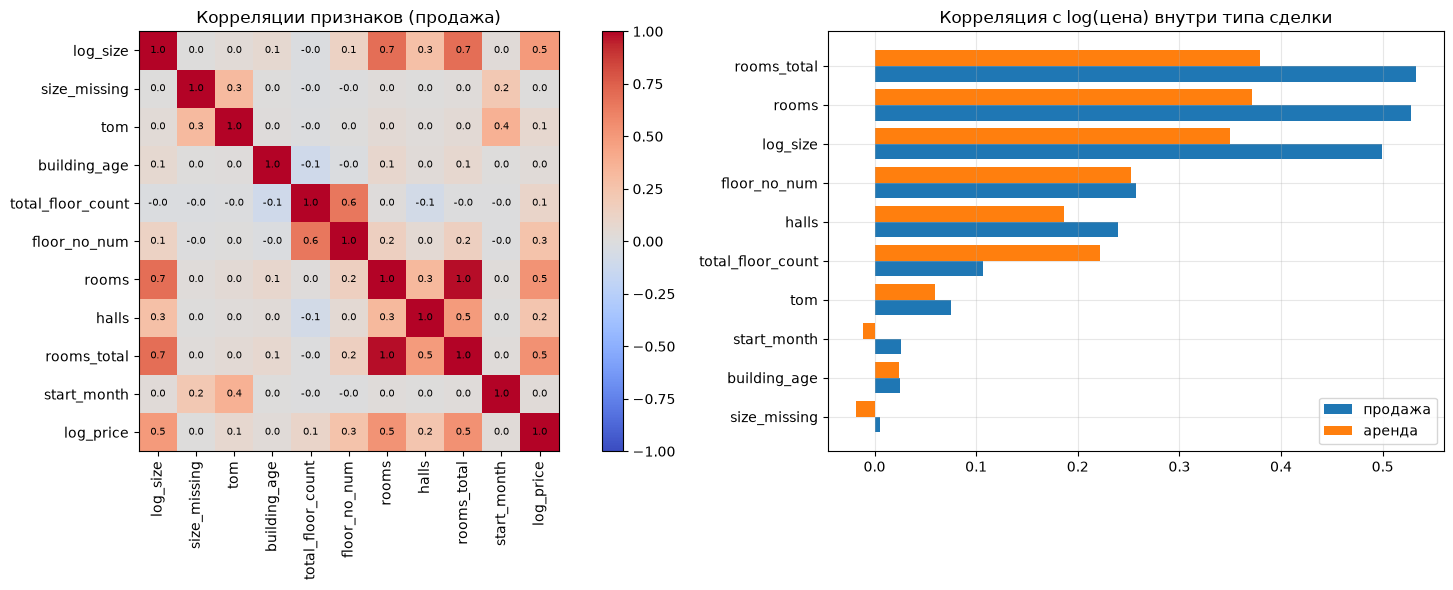

In [7]:
num_eda = X_all[num_cols].copy()
num_eda["log_price"] = np.log1p(y_all)
feat = [c for c in num_cols if c != "listing_type"]

# связь с ценой считаем внутри каждого типа сделки (иначе всё определяет listing_type)
corr_by = {lt: num_eda.loc[num_eda["listing_type"] == lt, feat + ["log_price"]].corr()["log_price"].drop("log_price")
           for lt in (1, 2)}
corr_df = pd.DataFrame({"продажа": corr_by[1], "аренда": corr_by[2]}).sort_values("продажа")
corr_sale = num_eda.loc[num_eda["listing_type"] == 1, feat + ["log_price"]].corr()

fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.4, 1]})
im = ax[0].imshow(corr_sale.values, cmap="coolwarm", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(corr_sale))); ax[0].set_xticklabels(corr_sale.columns, rotation=90)
ax[0].set_yticks(range(len(corr_sale))); ax[0].set_yticklabels(corr_sale.columns)
for i in range(len(corr_sale)):
    for j in range(len(corr_sale)):
        ax[0].text(j, i, f"{corr_sale.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax[0].grid(False); ax[0].set_title("Корреляции признаков (продажа)")
fig.colorbar(im, ax=ax[0], fraction=0.04)

y_pos = np.arange(len(corr_df))
ax[1].barh(y_pos - 0.2, corr_df["продажа"], 0.4, color="tab:blue", label="продажа")
ax[1].barh(y_pos + 0.2, corr_df["аренда"], 0.4, color="tab:orange", label="аренда")
ax[1].set_yticks(y_pos); ax[1].set_yticklabels(corr_df.index)
ax[1].set_title("Корреляция с log(цена) внутри типа сделки"); ax[1].legend()
plt.tight_layout(); plt.show()


In [8]:
size_miss = raw_summary["missing"].get("size", 0.0)
n_raw = raw_summary["rows"]
n_bad_cur = int(raw_summary["currency"].drop("TRY", errors="ignore").sum())
n_type3 = int(raw_summary["listing"].drop([1, 2], errors="ignore").sum())
med = train.groupby("listing_type")["price_w"].median()
c_sorted = corr_df["продажа"].abs().sort_values(ascending=False)
sub_share = train["sub_type"].value_counts(normalize=True).iloc[0] * 100
city_share = geo["city"].value_counts(normalize=True).head(3).sum() * 100
size_corr = {lt: np.log(eda.loc[(eda["listing_type"] == lt) & eda["size_n"].notna(), "size_n"]).corr(
                 np.log(eda.loc[(eda["listing_type"] == lt) & eda["size_n"].notna(), "price_w"])) for lt in (1, 2)}

fmt = lambda x: f"{x:,.0f}".replace(",", " ")

display(Markdown(f"""
**Что показал EDA**
- Исходных строк: **{fmt(n_raw)}**. Пропусков в `size` — **{size_miss:.0f}%**, в `price` и валюте — единицы процентов.
- Не в лирах (EUR/GBP/USD): **{fmt(n_bad_cur)}** строк; с типом сделки не 1/2: **{fmt(n_type3)}** строк. Они удалены: в тесте только TRY и типы 1/2.
- Цена сильно скошена и имеет выбросы, поэтому цена обрезана по 1–99% и берётся в логарифме.
- Продажа и аренда различаются по цене примерно в **{med[1] / med[2]:.0f} раз** (медианы {fmt(med[1])} и {fmt(med[2])} TRY), поэтому `listing_type` — ключевой признак.
- Самый частый подтип — {top_sub.index[0]} (**{sub_share:.0f}%** объявлений); три крупнейших города дают **{city_share:.0f}%** выборки.
- Связь log(площадь) — log(цена): продажа **{size_corr[1]:.2f}**, аренда **{size_corr[2]:.2f}** (корреляция на выборке).
- Среди числовых признаков при продаже сильнее всего с log(ценой) связан `{c_sorted.index[0]}` (|r| = {c_sorted.iloc[0]:.2f}).
"""))



**Что показал EDA**
- Исходных строк: **403 487**. Пропусков в `size` — **36%**, в `price` и валюте — единицы процентов.
- Не в лирах (EUR/GBP/USD): **2 095** строк; с типом сделки не 1/2: **2 242** строк. Они удалены: в тесте только TRY и типы 1/2.
- Цена сильно скошена и имеет выбросы, поэтому цена обрезана по 1–99% и берётся в логарифме.
- Продажа и аренда различаются по цене примерно в **225 раз** (медианы 270 000 и 1 200 TRY), поэтому `listing_type` — ключевой признак.
- Самый частый подтип — Daire (**88%** объявлений); три крупнейших города дают **46%** выборки.
- Связь log(площадь) — log(цена): продажа **0.50**, аренда **0.44** (корреляция на выборке).
- Среди числовых признаков при продаже сильнее всего с log(ценой) связан `rooms_total` (|r| = 0.53).


## 3. Модели
Сравниваем 7 разных алгоритмов (5 из них — ансамблевые: бэггинг и бустинг). Лучший выбирается по ошибке в логарифмической шкале на отложенной части (20%).


In [9]:
PARAMS = {
    "Ridge":             dict(alpha=1.0),
    "Decision Tree":     dict(max_depth=14, min_samples_leaf=20),
    "Random Forest":     dict(n_estimators=80, max_depth=18, min_samples_leaf=5, max_features=0.5,
                              bootstrap=True, max_samples=0.5),
    "Extra Trees":       dict(n_estimators=80, max_depth=20, min_samples_leaf=5, max_features=0.7,
                              bootstrap=True, max_samples=0.5),
    "Bagging":           dict(n_estimators=30, max_samples=0.5),
    "AdaBoost":          dict(n_estimators=50, learning_rate=0.5),
    "Gradient Boosting": dict(max_iter=400, learning_rate=0.08, max_leaf_nodes=63,
                              min_samples_leaf=40, l2_regularization=1.0, early_stopping=True),
}

KIND = {"Ridge": "линейная", "Decision Tree": "одно дерево",
        "Random Forest": "ансамбль (бэггинг)", "Extra Trees": "ансамбль (бэггинг)",
        "Bagging": "ансамбль (бэггинг)", "AdaBoost": "ансамбль (бустинг)",
        "Gradient Boosting": "ансамбль (бустинг)"}


def make_preprocessor():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                    ("ohe", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                          min_frequency=100, sparse_output=False))])
    te  = TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=RANDOM_STATE)
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols), ("te", te, te_cols)])


def make_estimator(name):
    p, rs = PARAMS[name], RANDOM_STATE
    return {
        "Ridge":             lambda: Ridge(**p),
        "Decision Tree":     lambda: DecisionTreeRegressor(random_state=rs, **p),
        "Random Forest":     lambda: RandomForestRegressor(random_state=rs, n_jobs=N_JOBS, **p),
        "Extra Trees":       lambda: ExtraTreesRegressor(random_state=rs, n_jobs=N_JOBS, **p),
        "Bagging":           lambda: BaggingRegressor(DecisionTreeRegressor(max_depth=12, min_samples_leaf=10),
                                                      random_state=rs, n_jobs=N_JOBS, **p),
        "AdaBoost":          lambda: AdaBoostRegressor(DecisionTreeRegressor(max_depth=8, min_samples_leaf=20),
                                                       random_state=rs, **p),
        "Gradient Boosting": lambda: HistGradientBoostingRegressor(random_state=rs, **p),
    }[name]()


def make_pipe(name):
    return Pipeline([("prep", make_preprocessor()), ("model", make_estimator(name))])


In [10]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=RANDOM_STATE, stratify=X_all["listing_type"])

rows, val_pred_log, fit_time = [], {}, {}
for name in PARAMS:
    t0 = time.time()
    pred_log = make_pipe(name).fit(X_tr, np.log1p(y_tr)).predict(X_val)
    val_pred_log[name] = pred_log
    pred = np.expm1(pred_log)
    rows.append({"model": name, "тип": KIND[name],
                 "val MAE":  mean_absolute_error(y_val, pred),
                 "val RMSE": np.sqrt(mean_squared_error(y_val, pred)),
                 "val R²":   r2_score(y_val, pred),
                 "RMSE (log)": np.sqrt(mean_squared_error(np.log1p(y_val), pred_log))})
    fit_time[name] = time.time() - t0
    print(f"{name}: {fit_time[name]:.0f} c")

cmp_df = pd.DataFrame(rows).set_index("model").round(3)
display(cmp_df)

best_name = cmp_df["RMSE (log)"].idxmin()
final_model = make_pipe(best_name).fit(X_all, np.log1p(y_all))     # финальное обучение на всех данных
print("Выбрана модель:", best_name)


Ridge: 2 c
Decision Tree: 4 c
Random Forest: 14 c
Extra Trees: 20 c
Bagging: 16 c
AdaBoost: 88 c
Gradient Boosting: 15 c


,тип,val MAE,val RMSE,val R²,RMSE (log)
model,,,,,
Ridge,линейная,91752.818,265047.327,0.667,0.412
Decision Tree,одно дерево,83677.908,235142.205,0.738,0.387
Random Forest,ансамбль (бэггинг),74517.437,213646.447,0.783,0.349
Extra Trees,ансамбль (бэггинг),75348.739,215025.867,0.781,0.350
Bagging,ансамбль (бэггинг),80477.722,225412.424,0.759,0.370
AdaBoost,ансамбль (бустинг),96091.598,264978.527,0.667,0.481
Gradient Boosting,ансамбль (бустинг),73700.601,208730.039,0.793,0.343


Выбрана модель: Gradient Boosting


## 3.1 Анализ моделей в графиках


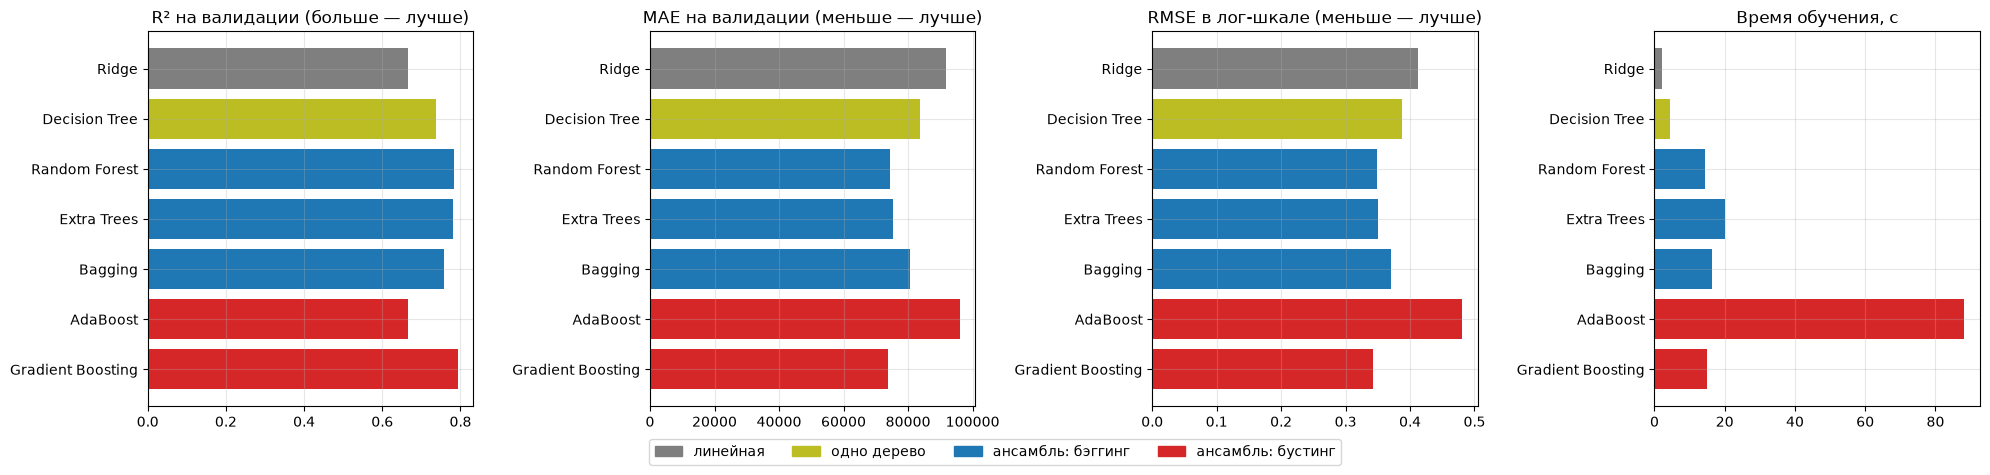

In [11]:
colors = cmp_df["тип"].map({"линейная": "tab:gray", "одно дерево": "tab:olive",
                            "ансамбль (бэггинг)": "tab:blue", "ансамбль (бустинг)": "tab:red"})
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, col, title in zip(ax[:3], ["val R²", "val MAE", "RMSE (log)"],
                         ["R² на валидации (больше — лучше)", "MAE на валидации (меньше — лучше)",
                          "RMSE в лог-шкале (меньше — лучше)"]):
    a.barh(cmp_df.index[::-1], cmp_df[col].values[::-1], color=colors.values[::-1])
    a.set_title(title)
ax[3].barh(list(fit_time)[::-1], list(fit_time.values())[::-1], color=colors.values[::-1])
ax[3].set_title("Время обучения, с")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=t) for t, c in
                    {"линейная": "tab:gray", "одно дерево": "tab:olive",
                     "ансамбль: бэггинг": "tab:blue", "ансамбль: бустинг": "tab:red"}.items()],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.show()


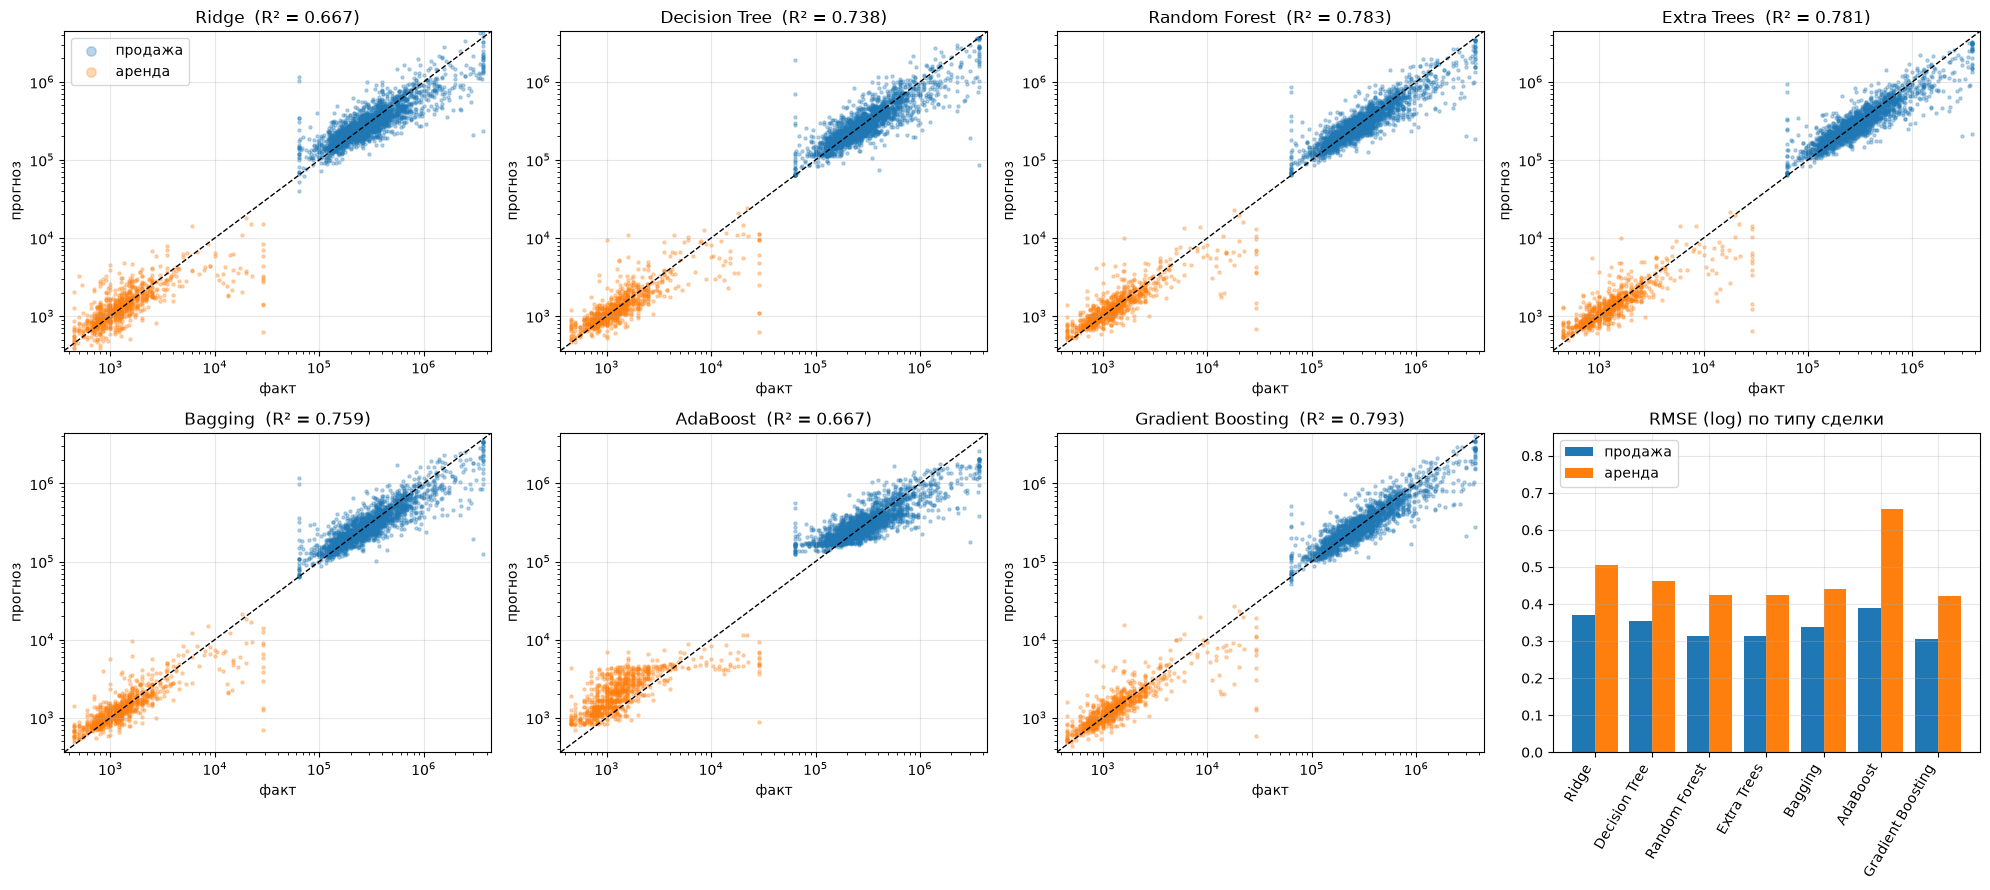

In [12]:
# Факт vs прогноз на валидации (лог-оси), по каждой модели
rs_idx = np.random.default_rng(RANDOM_STATE).choice(len(y_val), size=min(3000, len(y_val)), replace=False)
yv = y_val.values
lt_val = X_val["listing_type"].values

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()
lim = [yv.min() * 0.8, yv.max() * 1.2]
for a, name in zip(axes, PARAMS):
    p = np.expm1(val_pred_log[name])
    for lt, col in ((1, "tab:blue"), (2, "tab:orange")):
        m = rs_idx[lt_val[rs_idx] == lt]
        a.scatter(yv[m], p[m], s=5, alpha=0.3, color=col, label="продажа" if lt == 1 else "аренда")
    a.plot(lim, lim, "k--", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(lim); a.set_ylim(lim)
    a.set_title(f"{name}  (R² = {cmp_df.loc[name, 'val R²']:.3f})")
    a.set_xlabel("факт"); a.set_ylabel("прогноз")
axes[0].legend(markerscale=3)

# 8-я панель: RMSE в лог-шкале по типу сделки
w = 0.4
x = np.arange(len(PARAMS))
for k, (lt, name_lt, col) in enumerate(((1, "продажа", "tab:blue"), (2, "аренда", "tab:orange"))):
    m = lt_val == lt
    e = [np.sqrt(np.mean((val_pred_log[n][m] - np.log1p(yv[m])) ** 2)) for n in PARAMS]
    axes[7].bar(x + (k - 0.5) * w, e, w, color=col, label=name_lt)
axes[7].set_xticks(x); axes[7].set_xticklabels(list(PARAMS), rotation=60, ha="right")
axes[7].set_title("RMSE (log) по типу сделки")
axes[7].set_ylim(0, axes[7].get_ylim()[1] * 1.25); axes[7].legend(loc="upper left")
plt.tight_layout(); plt.show()


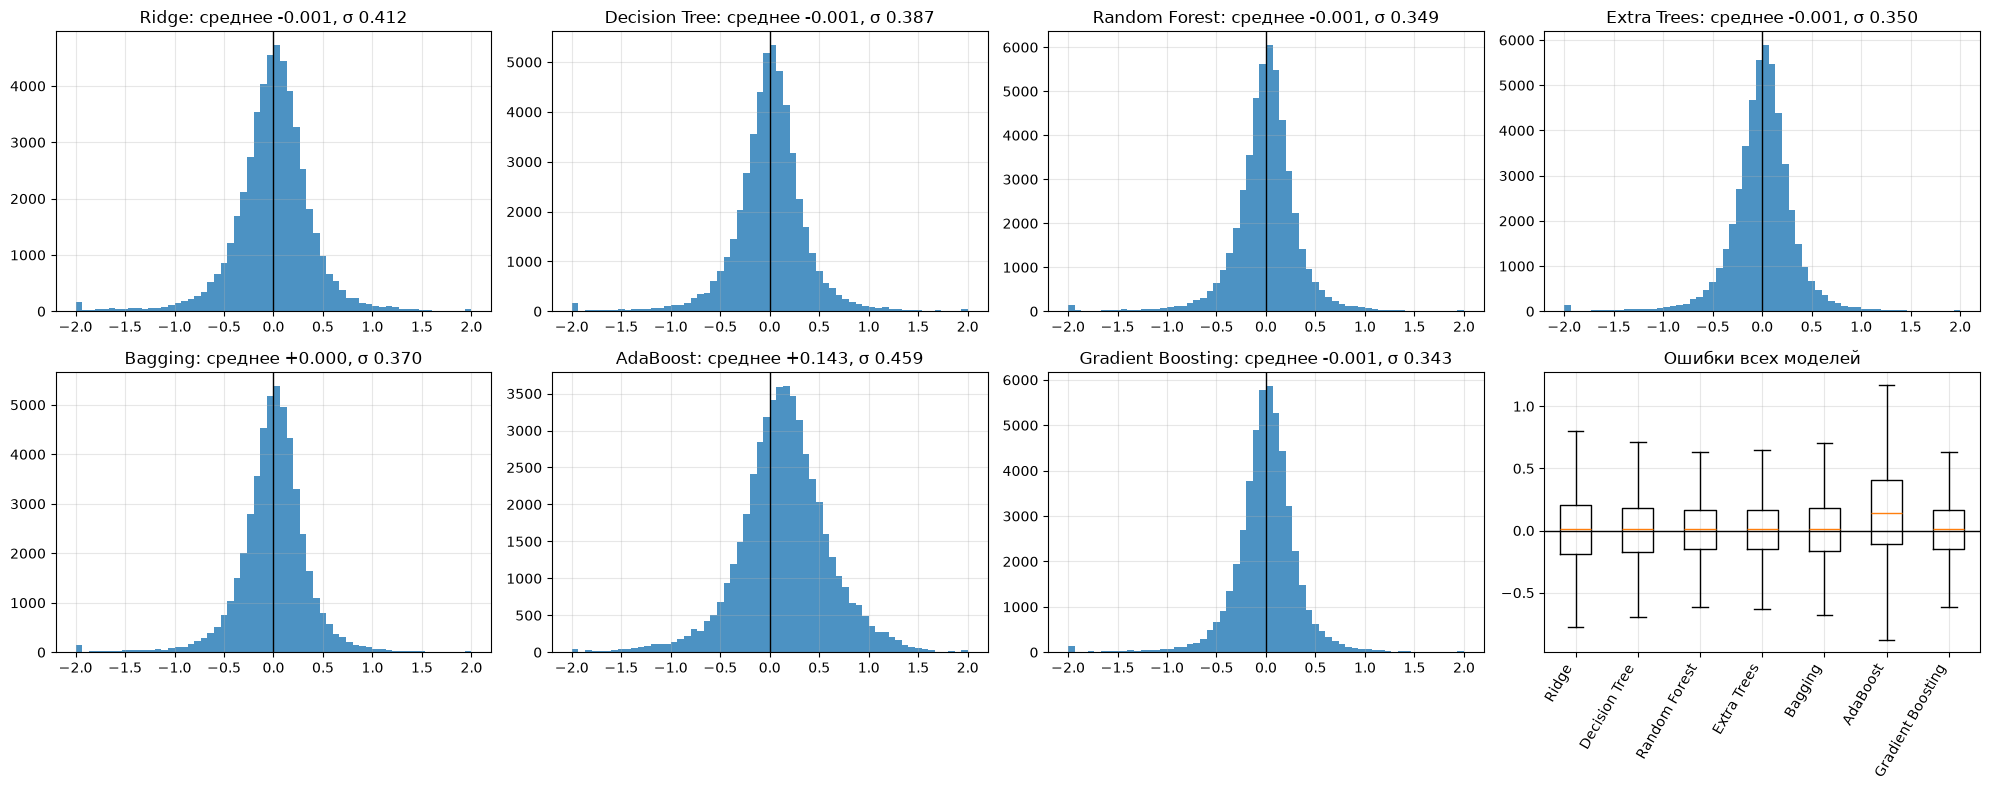

In [13]:
# Распределение ошибок (в лог-шкале: 0 — идеально, +0.69 — завышение в 2 раза)
res = {n: val_pred_log[n] - np.log1p(y_val.values) for n in PARAMS}
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()
for a, name in zip(axes, PARAMS):
    a.hist(np.clip(res[name], -2, 2), bins=60, color="tab:blue", alpha=0.8)
    a.axvline(0, color="k", lw=1)
    a.set_title(f"{name}: среднее {res[name].mean():+.3f}, σ {res[name].std():.3f}")
axes[7].boxplot([np.clip(r, -2, 2) for r in res.values()], showfliers=False)
axes[7].set_xticklabels(list(PARAMS), rotation=60, ha="right")
axes[7].axhline(0, color="k", lw=1); axes[7].set_title("Ошибки всех моделей")
plt.tight_layout(); plt.show()


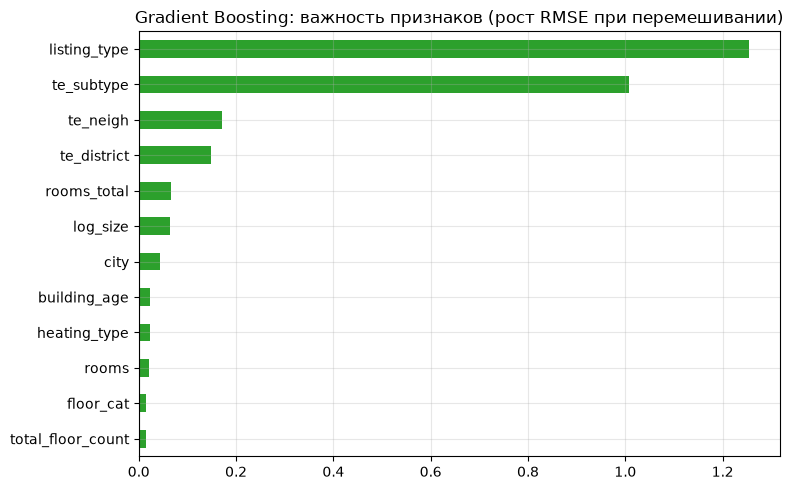

In [14]:
# Важность признаков для выбранной модели (перестановочная, по валидации)
from sklearn.inspection import permutation_importance

Xv = X_val.sample(min(5000, len(X_val)), random_state=RANDOM_STATE)
yv_log = np.log1p(y_val.loc[Xv.index])
r = permutation_importance(final_model, Xv, yv_log, n_repeats=3, random_state=RANDOM_STATE,
                           scoring="neg_root_mean_squared_error")
importance = pd.Series(r.importances_mean, index=Xv.columns).sort_values(ascending=False)
importance.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="tab:green",
                               title=f"{best_name}: важность признаков (рост RMSE при перемешивании)")
plt.tight_layout(); plt.show()


## 4. Тест (20 объектов) и метрики


In [15]:
test_pred = np.expm1(final_model.predict(X_test))

result = test.copy()
result["ФИО"], result["Группа"] = FIO, GROUP


def manual_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    mae  = np.abs(err).mean()
    rmse = np.sqrt((err ** 2).mean())
    r2   = 1 - (err ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()
    return mae, rmse, r2


m_mae, m_rmse, m_r2 = manual_metrics(y_test, test_pred)
s_mae, s_rmse, s_r2 = (mean_absolute_error(y_test, test_pred),
                       np.sqrt(mean_squared_error(y_test, test_pred)),
                       r2_score(y_test, test_pred))

metrics_df = pd.DataFrame({"Вручную": [m_mae, m_rmse, m_r2], "sklearn": [s_mae, s_rmse, s_r2]},
                          index=["MAE", "RMSE", "R²"])
metrics_df["Разница"] = (metrics_df["Вручную"] - metrics_df["sklearn"]).abs()
display(metrics_df.round(4))

result["MAE_manual"],  result["MAE_sklearn"]  = round(m_mae, 4),  round(s_mae, 4)
result["RMSE_manual"], result["RMSE_sklearn"] = round(m_rmse, 4), round(s_rmse, 4)
result["R2_manual"],   result["R2_sklearn"]   = round(m_r2, 4),   round(s_r2, 4)
result["predicted_price"] = test_pred.round(2)          # последний столбец

result.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")
display(result)


,Вручную,sklearn,Разница
MAE,128254.7993,128254.7993,0.0
RMSE,296896.8613,296896.8613,0.0
R²,0.7737,0.7737,0.0


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,...,price_currency,ФИО,Группа,MAE_manual,MAE_sklearn,RMSE_manual,RMSE_sklearn,R2_manual,R2_sklearn,predicted_price
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,132659.92
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,NaN,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,1039827.04
2,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,609500.02
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,NaN,1,NaN,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,92955.19
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,132601.29
5,100,Konut,Yazlık,1/12/19,NaN,1,46,1,10,9,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,470463.41
6,320,Konut,Yazlık,2/12/19,2/12/19,1,0,0,2,Müstakil,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,675742.21
7,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,153657.11
8,7810,Konut,Loft,12/30/18,1/29/19,1,30,NaN,4,NaN,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,637524.45
9,11,Konut,Müstakil Ev,11/13/18,11/26/18,1,13,0,1,Bahçe katı,...,TRY,Хабибуллин Артём Альбертович,23П-4,128254.7993,128254.7993,296896.8613,296896.8613,0.7737,0.7737,1322165.60


## 5. Разбор ошибок


In [16]:
an = test[["id", "sub_type", "listing_type", "size"]].copy()
an["price"]     = y_test.values
an["predicted"] = test_pred.round(0)
an["error"]     = an["price"] - an["predicted"]
an["APE, %"]    = (an["error"].abs() / an["price"] * 100).round(1)
display(an.sort_values("APE, %", ascending=False))


,id,sub_type,listing_type,size,price,predicted,error,"APE, %"
14,1942,Yalı Dairesi,2,NaN,750.0,3325.0,-2575.0,343.3
11,758,Çiftlik Evi,2,120.0,19000.0,669.0,18331.0,96.5
16,91731,Loft,2,NaN,16000.0,3385.0,12615.0,78.8
12,496,Komple Bina,2,905.0,12500.0,5136.0,7364.0,58.9
4,109,Kooperatif,1,1.0,300000.0,132601.0,167399.0,55.8
0,49,Kooperatif,1,1.0,300000.0,132660.0,167340.0,55.8
9,11,Müstakil Ev,1,125.0,2450000.0,1322166.0,1127834.0,46.0
1,506,Çiftlik Evi,1,250.0,1600000.0,1039827.0,560173.0,35.0
6,320,Yazlık,1,134.0,1000000.0,675742.0,324258.0,32.4
15,58,Villa,2,200.0,3600.0,4638.0,-1038.0,28.8


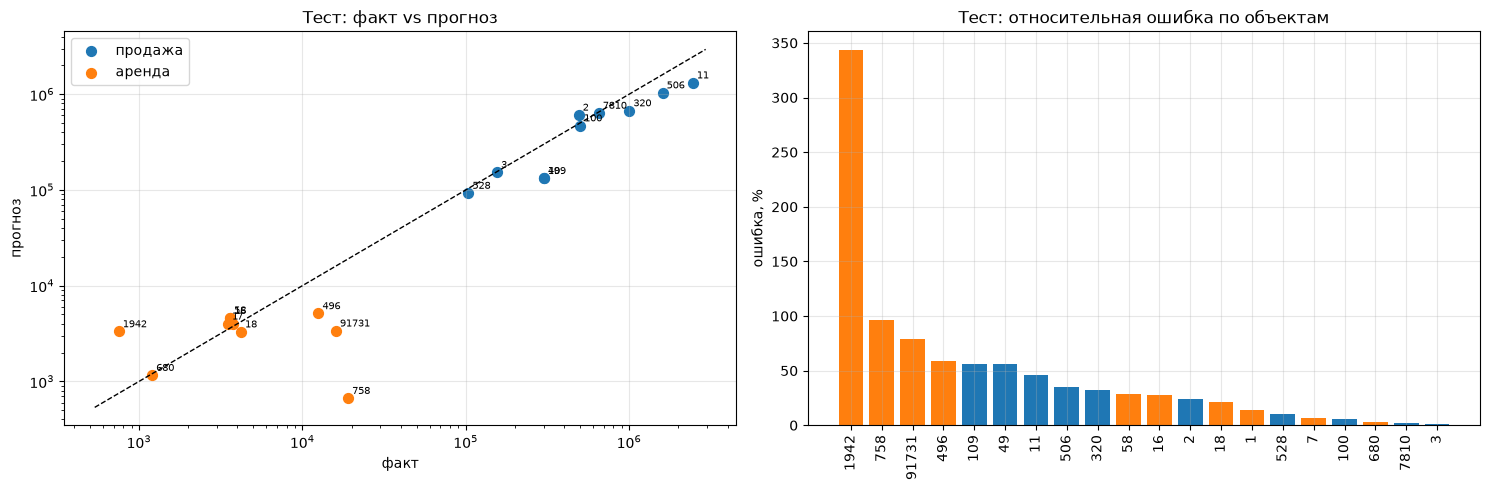

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for lt, name, col in ((1, "продажа", "tab:blue"), (2, "аренда", "tab:orange")):
    g = an[an["listing_type"] == lt]
    ax[0].scatter(g["price"], g["predicted"], s=50, color=col, label=name)
    for _, r_ in g.iterrows():
        ax[0].annotate(str(r_["id"]), (r_["price"], r_["predicted"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
lims = [an[["price", "predicted"]].min().min() * 0.8, an[["price", "predicted"]].max().max() * 1.2]
ax[0].plot(lims, lims, "k--", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("факт"); ax[0].set_ylabel("прогноз"); ax[0].set_title("Тест: факт vs прогноз"); ax[0].legend()

s_ = an.sort_values("APE, %", ascending=False)
ax[1].bar(s_["id"].astype(str), s_["APE, %"], color=s_["listing_type"].map({1: "tab:blue", 2: "tab:orange"}))
ax[1].set_xticklabels(s_["id"].astype(str), rotation=90)
ax[1].set_ylabel("ошибка, %"); ax[1].set_title("Тест: относительная ошибка по объектам")
plt.tight_layout(); plt.show()


## Отчёт


In [18]:
fmt = lambda x: f"{x:,.0f}".replace(",", " ")
b = cmp_df.loc[best_name]
ens = cmp_df[cmp_df["тип"].str.startswith("ансамбль")]
best_ens = ens["val R²"].idxmax()
weak = cmp_df.drop(ens.index)
best_weak = weak["val R²"].idxmax()
seg = {lt: manual_metrics(g["price"], g["predicted"]) for lt, g in an.groupby("listing_type")}
worst = an.sort_values("APE, %", ascending=False).head(3)
top_feat = ", ".join(f"`{f}`" for f in importance.head(3).index)
removed_txt = ", ".join(f"{k} — {fmt(v)}" for k, v in removed.items())

table_rows = "\n".join(
    f"| {n} | {cmp_df.loc[n, 'тип']} | {cmp_df.loc[n, 'val R²']:.3f} | {fmt(cmp_df.loc[n, 'val MAE'])} | {cmp_df.loc[n, 'RMSE (log)']:.3f} |"
    for n in cmp_df.sort_values("val R²", ascending=False).index)

display(Markdown(f"""
**Цель.** Предсказать цену объекта недвижимости (TRY) по описанию объявления.

**Данные.** Обучение на {fmt(len(train))} объявлениях, проверка на {len(test)} объектах. Удалено из обучения: {removed_txt}. Цена и площадь обрезаны по 1–99%, цена берётся в логарифме.

**Модели** (метрики на валидации, 20% обучающей выборки):

| Модель | Тип | R² | MAE | RMSE (log) |
|---|---|---|---|---|
{table_rows}

Выбрана **{best_name}** ({KIND[best_name]}): R² = {b['val R²']:.3f}, MAE = {fmt(b['val MAE'])}.

**Результат на тесте** ({len(test)} объектов): MAE = {fmt(m_mae)}, RMSE = {fmt(m_rmse)}, R² = {m_r2:.3f}. {'Ручной расчёт и `sklearn` совпадают.' if metrics_df['Разница'].max() < 1e-6 else 'Ручной расчёт и `sklearn` различаются.'}

**Анализ.**
- Лучшая ансамблевая модель ({best_ens}, R² = {cmp_df.loc[best_ens, 'val R²']:.3f}) {'лучше' if cmp_df.loc[best_ens, 'val R²'] > cmp_df.loc[best_weak, 'val R²'] else 'не лучше'} лучшей неансамблевой ({best_weak}, R² = {cmp_df.loc[best_weak, 'val R²']:.3f}).
- По типам сделки на тесте: продажа — R² = {seg[1][2]:.3f}, аренда — R² = {seg[2][2]:.3f}.
- Наибольшие ошибки: {', '.join(f"id {r['id']} ({r['sub_type']}, {r['APE, %']:.0f}%)" for _, r in worst.iterrows())}.
- Самые важные признаки: {top_feat}.

**Вывод.** Лучшая модель — {best_name}; R² на тесте = {m_r2:.3f}. Тест состоит из {len(test)} объектов, поэтому метрики приблизительные.
"""))



**Цель.** Предсказать цену объекта недвижимости (TRY) по описанию объявления.

**Данные.** Обучение на 250 000 объявлениях, проверка на 20 объектах. Удалено из обучения: тестовые объекты — 20, не TRY или тип сделки не 1/2 — 5 043, некорректная цена — 45. Цена и площадь обрезаны по 1–99%, цена берётся в логарифме.

**Модели** (метрики на валидации, 20% обучающей выборки):

| Модель | Тип | R² | MAE | RMSE (log) |
|---|---|---|---|---|
| Gradient Boosting | ансамбль (бустинг) | 0.793 | 73 701 | 0.343 |
| Random Forest | ансамбль (бэггинг) | 0.783 | 74 517 | 0.349 |
| Extra Trees | ансамбль (бэггинг) | 0.781 | 75 349 | 0.350 |
| Bagging | ансамбль (бэггинг) | 0.759 | 80 478 | 0.370 |
| Decision Tree | одно дерево | 0.738 | 83 678 | 0.387 |
| Ridge | линейная | 0.667 | 91 753 | 0.412 |
| AdaBoost | ансамбль (бустинг) | 0.667 | 96 092 | 0.481 |

Выбрана **Gradient Boosting** (ансамбль (бустинг)): R² = 0.793, MAE = 73 701.

**Результат на тесте** (20 объектов): MAE = 128 255, RMSE = 296 897, R² = 0.774. Ручной расчёт и `sklearn` совпадают.

**Анализ.**
- Лучшая ансамблевая модель (Gradient Boosting, R² = 0.793) лучше лучшей неансамблевой (Decision Tree, R² = 0.738).
- По типам сделки на тесте: продажа — R² = 0.647, аренда — R² = -0.466.
- Наибольшие ошибки: id 1942 (Yalı Dairesi, 343%), id 758 (Çiftlik Evi, 96%), id 91731 (Loft, 79%).
- Самые важные признаки: `listing_type`, `te_subtype`, `te_neigh`.

**Вывод.** Лучшая модель — Gradient Boosting; R² на тесте = 0.774. Тест состоит из 20 объектов, поэтому метрики приблизительные.
